# Gerchberg-Saxton ponderado consciente del dispositivo

**Pregunta:** ¿Puede el lazo de Gerchberg-Saxton ponderado absorber el crosstalk de píxeles y los otros límites del SLM dentro de sus iteraciones, en vez de combatirlos después, y cuánto supera a la línea base más fuerte en un dispositivo que los tiene?

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** notebooks 02 y 03 de este tema y notebook 01 del tema 01
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Todo método de los notebooks hasta aquí calcula un holograma para un SLM ideal y confía en el resultado. Un SLM real cuantiza la fase, la difumina entre píxeles vecinos (el crosstalk del cristal líquido), tiene un factor de llenado menor que 1 y parpadea. La respuesta habitual es una cámara en el lazo, que corrige las trampas después. El componente BS-1 del producto plantea otra pregunta: poner el modelo del dispositivo dentro del lazo ponderado, de modo que el holograma se calcule para el dispositivo. Primero verás cuán equivocado está sobre su propio resultado un método de modelo ideal en el dispositivo del caso C08, luego ejecutarás los mejores métodos que ofrece la literatura, Gerchberg-Saxton ponderado de fase fija y gradiente conjugado a través del operador de crosstalk, y después B1 del producto, dos semillas cada uno, evaluados en el dispositivo. La última medición encuentra dónde vive la ventaja de B1 y dónde cuesta.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import device_of, setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.device import device_focal_field
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b1_device_wgs
from pipeline.model.holo.methods.optim import m13_crosstalk_cg

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def on_device(phi, setup, traps, device):
    """Efficiency, uniformity and spread (percent) of a hologram as the device shows it, mean of four flicker draws."""
    rows = []
    for draw in range(4):
        field = device_focal_field(phi, setup, device, Rng(draw))
        i = metrics.trap_intensities(forward.trap_fields_from_fft(field, setup, traps))
        rows.append((metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)))
    return np.mean(rows, axis=0)

numpy 2.4.6
matplotlib 3.11.2


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros, cubierto por la licencia del repositorio; los parámetros de crosstalk son los ajustados por Schroff et al. 2023 (https://doi.org/10.1038/s41598-023-30296-6).
- Archivo leído: `data/examples/cases.json`, caso C08: 64 trampas sobre un SLM de 128 por 128 píxeles con 4 bits de fase, crosstalk de ancho ajustado 1,24 y exponente 1,8, un factor de llenado de 0,85 y un parpadeo de 0,05 rad, y dos semillas contadas desde la semilla del caso.

In [2]:
# case C08: 64 traps on a 128 x 128 pixel SLM with 4 bits, pixel crosstalk, a fill factor of 0.85 and a little flicker
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C08_device_limited"]
setup = setup_of(rec)
device = device_of(rec)
target = target_of(rec)
traps = target.traps
budget = Budget(rec["budget"]["iterations"])
seeds = [rec["seed"], rec["seed"] + 1]
print(f"{len(traps)} trampas, {setup.n_pix} x {setup.n_pix} píxeles, {device.bit_depth} bits,")
print(f"crosstalk (sigma, q): {device.crosstalk}")
print(f"factor de llenado {device.fill_factor}, parpadeo {device.flicker_rad} rad")

64 trampas, 128 x 128 píxeles, 4 bits,
crosstalk (sigma, q): (1.24, 1.8)
factor de llenado 0.85, parpadeo 0.05 rad


## Método

El modelo de dispositivo del producto actúa sobre la fase mostrada en cuatro pasos: cuantización a $2^b$ niveles, una curva de respuesta, ruido de parpadeo y el crosstalk, una convolución circular de la fase sobremuestreada con un núcleo cuya función de transferencia es $\exp[-(|k_x|^q + |k_y|^q)/\sigma^q]$, seguido de la apertura del píxel (Schroff et al. 2023, https://doi.org/10.1038/s41598-023-30296-6). Un holograma se juzga por el campo focal de esa fase mostrada. Los métodos de los notebooks anteriores no conocen el dispositivo: Gerchberg-Saxton ponderado de fase fija (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178) itera el modelo ideal y se detiene cuando es uniforme en el modelo ideal. Las métricas son las del tema 01, calculadas en el dispositivo y promediadas sobre cuatro sorteos del parpadeo, porque el parpadeo es aleatorio y un holograma debe ser bueno en el dispositivo promedio.

La primera celda ejecuta Gerchberg-Saxton ponderado (M06) y Gerchberg-Saxton ponderado de fase fija (M07) durante las 30 iteraciones del caso e imprime dos lecturas del mismo holograma: la dispersión que el método ve en el modelo ideal, que es la última entrada de su historial, y la dispersión que muestra el dispositivo.

In [3]:
# the ideal model against the device: weighted GS and phase-fixed WGS judge themselves on the ideal model
ideal_runs = {}
for name, method in (("M06", m06_gsw), ("M07", m07_phase_fixed_wgs)):
    ideal_runs[name] = method.run(setup, target, budget=budget, rng=Rng(seeds[0]))
    last = ideal_runs[name].history[-1]
    shown = on_device(ideal_runs[name].phi, setup, traps, device)
    print(f"{name}: juicio propio sobre el modelo ideal: sigma = {last['rel_std']:.3f} %, e = {last['efficiency']:.4f}")
    print(f"     en el dispositivo: sigma = {shown[2]:.3f} %, e = {shown[0]:.4f}")

M06: juicio propio sobre el modelo ideal: sigma = 0.848 %, e = 0.8033
     en el dispositivo: sigma = 15.247 %, e = 0.6794
M07: juicio propio sobre el modelo ideal: sigma = 0.013 %, e = 0.7989
     en el dispositivo: sigma = 14.664 %, e = 0.6780


Una respuesta natural es que el método no ha iterado lo suficiente. La celda ejecuta M07 durante 100 iteraciones y lo lee en el dispositivo junto al holograma de 30 iteraciones.

In [4]:
# more iterations of the ideal-model method do not help: 100 iterations of phase-fixed WGS, read on the device
long_run = m07_phase_fixed_wgs.run(setup, target, budget=Budget(100), rng=Rng(seeds[0]))
for label, res in (("30", ideal_runs["M07"]), ("100", long_run)):
    shown = on_device(res.phi, setup, traps, device)
    print(f"M07 {label:>3s} iteraciones: en el dispositivo: sigma = {shown[2]:.3f} %")
    print(f"     u = {shown[1]:.4f}, e = {shown[0]:.4f}")

M07  30 iteraciones: en el dispositivo: sigma = 14.664 %
     u = 0.7216, e = 0.6780
M07 100 iteraciones: en el dispositivo: sigma = 14.664 %
     u = 0.7216, e = 0.6780


## Estado del arte

Dos líneas de trabajo responden a la brecha. La primera es la retroalimentación con cámara, que corrige las trampas después de hacer el holograma y que el producto emula en notebooks de los temas posteriores. La segunda pone el modelo de crosstalk dentro de la optimización: Schroff et al. (2023) lo usan con gradiente conjugado en potenciales moldeados, y M13 del producto es ese método para las trampas de este caso, con el gradiente a través de la adjunta del operador de crosstalk en forma cerrada. Es la línea base más fuerte para un dispositivo con crosstalk, pues optimiza directamente la intensidad consciente del dispositivo, al precio de muchas iteraciones; la línea base más fuerte para el modelo ideal es Gerchberg-Saxton ponderado de fase fija. La celda ejecuta M13 en el dispositivo e imprime la dispersión, la uniformidad y la eficiencia en el dispositivo.

La celda ejecuta M13 con el dispositivo del caso durante 12 iteraciones, el mismo número de pasos de gradiente conjugado que recibe B1 (4 iteraciones externas de 3), desde el mismo inicio aleatorio, y lee el resultado en el dispositivo. Una corrida hasta la convergencia toma unas cien iteraciones y unos diez minutos en la máquina de desarrollo, demasiado para un notebook, de modo que lo que mide la celda es un inicio en frío sin converger de la línea base más fuerte, y los Resultados dicen qué respalda y qué no respalda eso.

In [5]:
# the other way to use the device model: conjugate gradient through the crosstalk operator (M13), 12 iterations
cg_run = m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(12), rng=Rng(seeds[0]))
cg_numbers = on_device(cg_run.phi, setup, traps, device)
print(f"M13 12 iteraciones: en el dispositivo: sigma = {cg_numbers[2]:.3f} %")
print(f"     u = {cg_numbers[1]:.4f}, e = {cg_numbers[0]:.4f}")

M13 12 iteraciones: en el dispositivo: sigma = 57.855 %
     u = 0.0193, e = 0.1986


## Más allá del estado del arte

La afirmación BS-1 del producto: conservar los pesos de Gerchberg-Saxton ponderado, $w_m \leftarrow w_m\langle r\rangle/r_m$, con $r_m$ medido en el campo focal del dispositivo, y reemplazar la actualización de fase por unos pocos pasos de gradiente conjugado sobre la pérdida de intensidad consciente del dispositivo, a través del cuantizador de paso directo y del operador de crosstalk. Los pesos dan al lazo su memoria, y los pasos de gradiente le dan el dispositivo. La brecha que llena es que el modelo de crosstalk se había usado solo con gradiente conjugado en potenciales moldeados, nunca dentro de un lazo ponderado para arreglos de trampas (Schroff et al. 2023). El componente es B1 en el código. Las pruebas que siguen son las que pueden refutarlo: dos semillas contra Gerchberg-Saxton ponderado de fase fija, una semilla contra el gradiente conjugado con el dispositivo, y un recorrido de la intensidad del crosstalk para ver de dónde viene la ventaja y qué cuesta.

La celda ejecuta B1, con 4 iteraciones externas de 3 pasos de gradiente conjugado cada una, para las dos semillas, y M07 para las mismas semillas, lee ambos en el dispositivo e imprime el promedio, el rango de la dispersión y las razones.

In [6]:
# the claim, BS-1: weighted GS whose phase update is a few conjugate-gradient steps through the device model
b1_runs = [b1_device_wgs.run(setup, target, device=device, budget=Budget(4), rng=Rng(s)) for s in seeds]
b1_numbers = np.array([on_device(r.phi, setup, traps, device) for r in b1_runs])
m07_runs = [m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(s)) for s in seeds]
m07_numbers = np.array([on_device(r.phi, setup, traps, device) for r in m07_runs])
for name, rows in (("M07", m07_numbers), ("B1", b1_numbers)):
    e, u, sigma = rows.mean(axis=0)
    low, high = rows[:, 2].min(), rows[:, 2].max()
    print(f"{name}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.3f} % (rango {low:.3f} a {high:.3f})")
ratio = m07_numbers[:, 2].mean() / b1_numbers[:, 2].mean()
print(f"dispersión de M07 sobre la de B1: {ratio:.1f}")
print(f"eficiencia de B1 sobre la de M07: {b1_numbers[:, 0].mean() / m07_numbers[:, 0].mean():.3f}")
print(f"dispersión de M13 sobre la de B1 con la primera semilla: {cg_numbers[2] / b1_numbers[0, 2]:.2f}")

M07: e = 0.6759, u = 0.7357, sigma = 13.485 % (rango 12.307 a 14.664)
B1: e = 0.6431, u = 0.8631, sigma = 6.343 % (rango 6.174 a 6.512)
dispersión de M07 sobre la de B1: 2.1
eficiencia de B1 sobre la de M07: 0.951
dispersión de M13 sobre la de B1 con la primera semilla: 8.88


El crosstalk es solo uno de los límites del dispositivo. La celda mantiene los 4 bits, el factor de llenado y el parpadeo y cambia solo el crosstalk, de ninguno a un ancho de 0,8 (fuerte; un ancho menor significa más difuminado), ejecutando B1 y leyendo M07 en cada dispositivo para la primera semilla.

In [7]:
# where does the advantage live? the crosstalk strength from none to strong, first seed, same bits and fill factor
rows = {}
levels = (("ninguno", None), ("1.24", (1.24, 1.8)), ("0.8", (0.8, 1.8)))
for label, crosstalk in levels:
    dev = replace(device, crosstalk=crosstalk)
    ours = b1_runs[0]
    if label != "1.24":
        ours = b1_device_wgs.run(setup, target, device=dev, budget=Budget(4), rng=Rng(seeds[0]))
    rows[label] = (on_device(m07_runs[0].phi, setup, traps, dev), on_device(ours.phi, setup, traps, dev))
    print(f"{label:>5s}: M07 sigma = {rows[label][0][2]:7.3f} %, B1 sigma = {rows[label][1][2]:7.3f} %")

ninguno: M07 sigma =   4.395 %, B1 sigma =   0.760 %
 1.24: M07 sigma =  14.664 %, B1 sigma =   6.512 %
  0.8: M07 sigma =  26.598 %, B1 sigma =  17.267 %


La primera figura grafica la dispersión relativa de las trampas en el dispositivo de C08 para los cuatro métodos, el promedio de dos semillas para M07 y B1 y la primera semilla para M13 y M06.

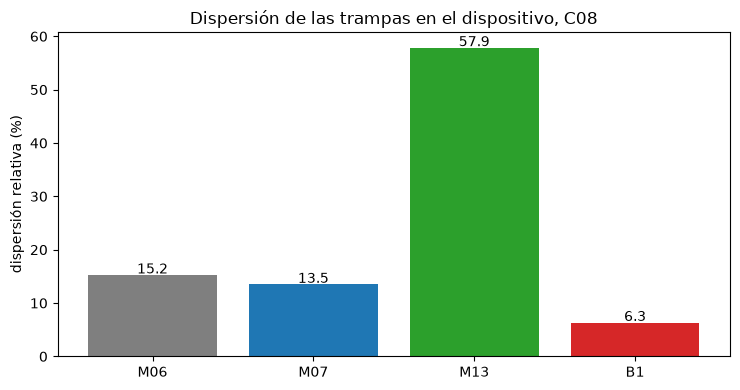

In [8]:
# the spread of the traps on the device for the four methods, mean of three seeds where there are three
fig, ax = plt.subplots(figsize=(7.5, 4))
bars = {
    "M06": on_device(ideal_runs["M06"].phi, setup, traps, device)[2],
    "M07": m07_numbers[:, 2].mean(),
    "M13": cg_numbers[2],
    "B1": b1_numbers[:, 2].mean(),
}
ax.bar(list(bars), list(bars.values()), color=["C7", "C0", "C2", "C3"])
for k, value in enumerate(bars.values()):
    ax.text(k, value + 0.3, f"{value:.1f}", ha="center")
ax.set_ylabel("dispersión relativa (%)")
ax.set_title("Dispersión de las trampas en el dispositivo, C08")
fig.tight_layout()
plt.show()

Las barras bajan en el orden de cuánto del dispositivo conoce cada método, con una excepción. M06, que no conoce nada, tiene una dispersión de 15,2 por ciento; M07, que converge en el modelo ideal, 13,5; B1, que tiene el dispositivo y los pesos, 6,3. Los métodos de modelo ideal se juzgaron en 0,848 y 0,013 por ciento, de modo que su propio informe estaba equivocado en tres órdenes de magnitud, y cien iteraciones no cambiaron un dígito del resultado de M07. La excepción es M13, con 57,9 por ciento y una eficiencia de 0,1986: con 12 iteraciones desde un inicio aleatorio el gradiente conjugado no ha convergido y no es una línea base justa, lo que dice la Respuesta de más abajo. La figura no muestra la eficiencia que paga cada método.

La segunda figura tiene dos paneles. A la izquierda, la razón de la dispersión de M07 a la de B1 contra el ancho del crosstalk, de ninguno al más fuerte. A la derecha, la eficiencia de ambos.

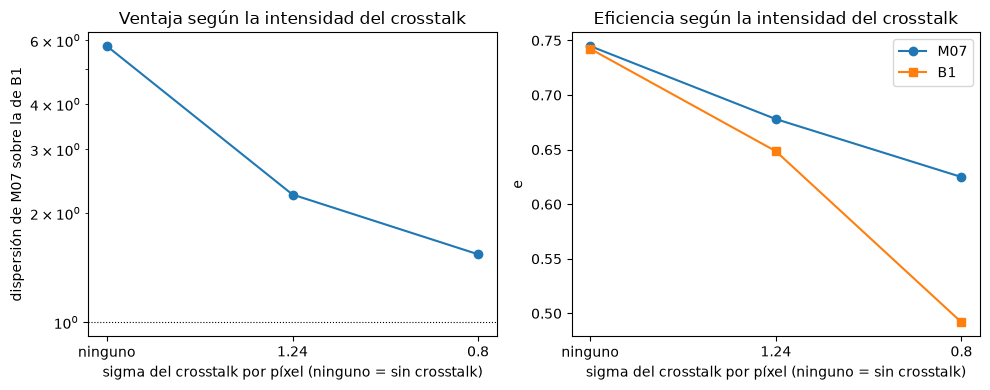

In [9]:
# the ratio of the two spreads against the crosstalk strength, and the efficiency each method keeps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
labels = list(rows)
ax1.semilogy(labels, [rows[k][0][2] / rows[k][1][2] for k in labels], "o-")
ax1.axhline(1.0, color="k", lw=0.8, ls=":")
ax1.set_xlabel("sigma del crosstalk por píxel (ninguno = sin crosstalk)")
ax1.set_ylabel("dispersión de M07 sobre la de B1")
ax1.set_title("Ventaja según la intensidad del crosstalk")
ax2.plot(labels, [rows[k][0][0] for k in labels], "o-", label="M07")
ax2.plot(labels, [rows[k][1][0] for k in labels], "s-", label="B1")
ax2.set_xlabel("sigma del crosstalk por píxel (ninguno = sin crosstalk)")
ax2.set_ylabel("e")
ax2.set_title("Eficiencia según la intensidad del crosstalk")
ax2.legend()
fig.tight_layout()
plt.show()

La ventaja no es solo un efecto del crosstalk. Sin ningún crosstalk, con solo 4 bits, un factor de llenado de 0,85 y parpadeo, M07 tiene una dispersión de 4,395 por ciento y B1 0,760, una razón de 5,8, porque B1 ve también el cuantizador y la apertura. Cuando el crosstalk crece ambos empeoran y la razón baja: 2,25 con el 1,24 del caso y 1,54 con 0,8, donde B1 aún tiene 17,267 por ciento frente a 26,598. El panel derecho muestra el precio. Sin crosstalk B1 y M07 tienen casi la misma eficiencia; con 1,24 B1 tiene 0,648 frente a 0,678 y con 0,8 tiene 0,49 frente a 0,62, de modo que con crosstalk fuerte B1 gasta potencia en ser uniforme y termina con un holograma mejor en dispersión y mucho peor en eficiencia. El recorrido usa una semilla por punto y un número fijo de pasos, y no dice nada de dispositivos con otra profundidad de bits.

## Resultados

**Respuesta:** Sí frente a la línea base de fase fija, y sin resolver frente al gradiente conjugado. En el dispositivo de C08 los métodos de modelo ideal se equivocan sobre sí mismos: Gerchberg-Saxton ponderado de fase fija juzga su propio holograma con una dispersión de 0,013 por ciento y el dispositivo muestra 14,664 por ciento, y 100 iteraciones en vez de 30 no cambian nada. B1, con 4 iteraciones externas de 3 pasos de gradiente conjugado, llega a 6,343 por ciento en promedio sobre dos semillas (6,174 a 6,512), frente a 13,485 por ciento de M07 (12,307 a 14,664), un factor de 2,1 con 0,951 de la eficiencia de M07; la uniformidad es 0,8631 frente a 0,7357. El gradiente conjugado a través del operador de crosstalk, M13, recibió aquí solo 12 iteraciones y termina en 57,855 por ciento con una eficiencia de 0,1986, que es una corrida sin converger y no una medición de esa línea base: el notebook no muestra que B1 la supere en la convergencia. La ventaja sobre M07 depende del dispositivo: 5,8 veces sin crosstalk, 2,25 con el crosstalk del caso, 1,54 con un ancho de 0,8, donde B1 cede eficiencia (el panel derecho muestra cerca de 0,49 frente a 0,62). BS-1 se sostiene frente a Gerchberg-Saxton ponderado de fase fija en este dispositivo y con estas semillas, por un factor de dos y no de un orden de magnitud, con un costo en eficiencia.

## Resumen

Un holograma calculado para un SLM ideal se equivoca sobre sí mismo en órdenes de magnitud en un dispositivo con 4 bits y crosstalk, y más iteraciones no lo reparan. Poner el dispositivo en el lazo dentro de la iteración ponderada, como hace B1, reduce la dispersión en un factor de dos frente al estado del arte de modelo ideal, a un costo de cerca de cinco por ciento de la eficiencia que crece cuando el crosstalk es fuerte. Lo que no se prueba es la comparación con un gradiente conjugado ejecutado hasta la convergencia, otra profundidad de bits o factor de llenado, el parpadeo dentro del lazo y más de dos semillas.

## Referencias

- Schroff et al., "Accurate holographic light potentials using pixel crosstalk modelling", Scientific Reports 13 (2023), https://doi.org/10.1038/s41598-023-30296-6.
- Kim, Kim, Lee y Ahn, "Gerchberg-Saxton algorithm with phase fixing for tweezer arrays", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.